Shape: (500, 6)
   Area  Bedrooms  Bathrooms  Age Location   Price
0  3674         4          3    9    Rural  844132
1  1360         2          2   24     City  249754
2  1794         3          2   22     City  381538
3  1630         4          3   16     City  433871
4  1595         5          3   14   Suburb  510751

Nulls: 0
             Area    Bedrooms   Bathrooms         Age          Price
count   500.00000  500.000000  500.000000  500.000000     500.000000
mean   2319.38400    3.052000    2.000000   15.084000  486092.152000
std    1003.67328    1.462043    0.818131    8.717392  175560.225517
min     501.00000    1.000000    1.000000    0.000000   71904.000000
25%    1478.75000    2.000000    1.000000    8.000000  346878.250000
50%    2297.50000    3.000000    2.000000   15.000000  492580.500000
75%    3208.00000    4.000000    3.000000   23.000000  623115.000000
max    3999.00000    5.000000    3.000000   29.000000  883988.000000


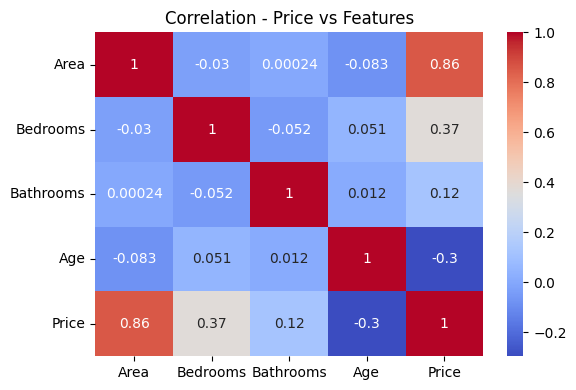

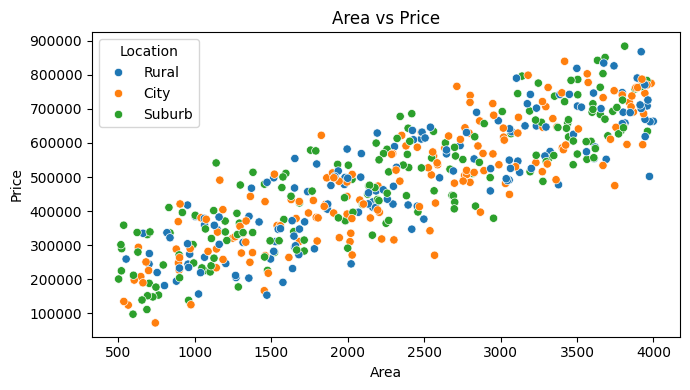


--- MODEL RESULT ---
R2 Score: 0.975
RMSE: 27986.42

Coefficients:
Area: 148.7
Bedrooms: 49728.81
Bathrooms: 30735.72
Age: -4937.03
Location_Rural: -3989.36
Location_Suburb: -2702.5


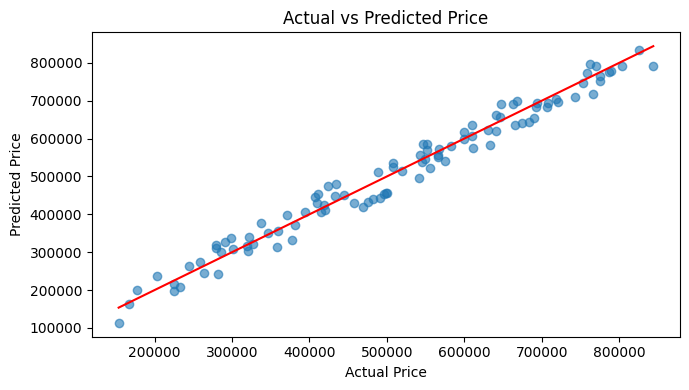


--- INTERPRETATION ---
1. Area badhne se Price sabse zyada badhta hai.
2. Bedrooms aur Bathrooms bhi Price badhate hai.
3. Ghar purana hone se Price kam hota hai.


In [1]:
# LEVEL 2 - TASK 1 - HOUSE PRICE PREDICTION
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Housing Data Khud Banate Hai - Link ka chakkar khatam
np.random.seed(42)
n = 500
df = pd.DataFrame({
    'Area': np.random.randint(500, 4000, n),
    'Bedrooms': np.random.randint(1, 6, n),
    'Bathrooms': np.random.randint(1, 4, n),
    'Age': np.random.randint(0, 30, n),
    'Location': np.random.choice(['City', 'Suburb', 'Rural'], n)
})
# Price ka formula - Area sabse zyada affect karega
df['Price'] = (df['Area']*150 + df['Bedrooms']*50000 + df['Bathrooms']*30000 - df['Age']*5000 + np.random.randint(-50000, 50000, n))

print("Shape:", df.shape)
print(df.head())
print("\nNulls:", df.isnull().sum().sum())
print(df.describe())

# 2. Correlation Heatmap
plt.figure(figsize=(6,4))
sns.heatmap(df[['Area','Bedrooms','Bathrooms','Age','Price']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation - Price vs Features')
plt.tight_layout(); plt.show()

# 3. Area vs Price Scatter
plt.figure(figsize=(7,4))
sns.scatterplot(data=df, x='Area', y='Price', hue='Location')
plt.title('Area vs Price')
plt.tight_layout(); plt.show()

# 4. One-Hot Encoding + Train Test Split
df_encoded = pd.get_dummies(df, columns=['Location'], drop_first=True)
X = df_encoded.drop('Price', axis=1)
y = df_encoded['Price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("\n--- MODEL RESULT ---")
print("R2 Score:", round(r2_score(y_test, y_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("\nCoefficients:")
for col, coef in zip(X.columns, model.coef_):
    print(f"{col}: {round(coef, 2)}")

# 6. Actual vs Predicted Graph
plt.figure(figsize=(7,4))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
plt.xlabel('Actual Price'); plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Price')
plt.tight_layout(); plt.show()

print("\n--- INTERPRETATION ---")
print("1. Area badhne se Price sabse zyada badhta hai.")
print("2. Bedrooms aur Bathrooms bhi Price badhate hai.")
print("3. Ghar purana hone se Price kam hota hai.")